In [22]:
import os
from pathlib import Path

base = Path("/home/xilinx/jupyter_notebooks/qick/firmware/projects/qick_tprocv2_216_16intp")
out_dir = base / "out"

# 1. Clean up the non-working links
for name in ["qick_216.bit", "qick_216.hwh"]:
    f = out_dir / name
    if f.exists() or f.is_symlink():
        f.unlink()

# 2. Create actual, native OS-level relative symlinks
os.symlink("../top/top.runs/impl_1/d_1_wrapper.bit", str(out_dir / "qick_216.bit"))
os.symlink("../top/top.gen/sources_1/bd/d_1/hw_handoff/d_1.hwh", str(out_dir / "qick_216.hwh"))

print("Native Linux symlinks successfully recreated!")

Native Linux symlinks successfully recreated!


In [23]:
from qick import QickSoc

# Load the firmware bitstream
soc = QickSoc("/home/xilinx/jupyter_notebooks/qick/firmware/projects/qick_tprocv2_216_16intp/out/qick_216.bit", external_clk=True)

soccfg = soc

# Print to check soc details and show code has run
print(soc)

configuring reference clock chips, as requested
LMK04828 clock reference = 245.760 MHz, LMX2594 clock synth = 491.520 MHz
QICK running on ZCU216, software version 0.2.422

Firmware configuration (built Fri Jul 24 16:45:36 2026):

	Global clocks (MHz): tProc dispatcher timing 430.080, RF reference 245.760
	Groups of related clocks: [tProc core clock, tProc timing clock, DAC tile 0, DAC tile 1, DAC tile 2, DAC tile 3], [ADC tile 2]

	16 signal generator channels:
	0:	axis_sg_int4_v2 - fs=6881.280 Msps, fabric=430.080 MHz
		envelope memory: 8192 complex samples (19.048 us)
		32-bit DDS, range=1720.320 MHz
		DAC tile 0, blk 0 is 0_228 on JHC1, or QICK box DAC port 0
	1:	axis_sg_int4_v2 - fs=6881.280 Msps, fabric=430.080 MHz
		envelope memory: 8192 complex samples (19.048 us)
		32-bit DDS, range=1720.320 MHz
		DAC tile 0, blk 1 is 1_228 on JHC2, or QICK box DAC port 1
	2:	axis_sg_int4_v2 - fs=6881.280 Msps, fabric=430.080 MHz
		envelope memory: 8192 complex samples (19.048 us)
		32-bit DDS,

In [26]:
"""
Plays a rectangular, a Tukey, a flat-top, and a Blackman pulse back to back, all with
the SAME peak amplitude and the SAME area (so the same rotation for a resonant drive).
Each pulse's duration is solved for automatically, then the ideal Fourier transforms
are plotted on a common dB scale so the spectra are directly comparable.

Run on the board with `soc` / `soccfg` already defined; set RUN_ON_HW = False to only
generate the plots (useful off-board).
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal.windows import tukey, blackman
from qick.helpers import gauss

RUN_ON_HW = True

# ----------------------------------------------------------------------------
# User parameters (times in us, frequencies in MHz, gain in [-1, 1])
# ----------------------------------------------------------------------------
cfg = {
    "gen_ch":      0,       # must be a full-speed or interpolated gen (NOT a mux gen); check print(soc)
    "nqz":         1,
    "freq":        500.0,   # carrier frequency
    "gain":        0.5,     # peak amplitude, identical for every pulse

    "area_us":     1.5,     # every pulse has the area of a rectangle this long at the same peak
    "gap":         0.5,     # dead time between pulses

    "taper_len":   0.8,     # Tukey: total cosine-taper time (rise + fall); match ramp_len for fairness
    "ramp_len":    0.2,     # flat-top: total Gaussian ramp length (rise + fall)
    "ramp_sigma":  0.025,    # flat-top: Gaussian sigma (ramp half-length = 4 sigma)

    "trig_pin":    0,       # tProc trigger output for a scope (set None to disable)
    "reps":        100000,  # repeat the sequence so it is easy to see on a scope
    "final_delay": 10.0,    # idle time after each repetition
}

PULSE_ORDER = ["Rectangular", "Tukey", "Flat-top", "Blackman"]   # play order

In [27]:
# ----------------------------------------------------------------------------
# Pulse design: every envelope has peak 1; its length (whole fabric clocks) is
# chosen so its area matches cfg["area_us"]. Used for BOTH the hardware and the
# plots, so the plotted spectra are exactly what the DAC plays.
# ----------------------------------------------------------------------------
def gauss_ramp(cfg, f_fabric, spc):
    """Gaussian ramp, even number of fabric clocks, same formula as QickProgramV2.add_gauss."""
    fs = f_fabric * spc
    n_ramp = 2 * int(np.round(cfg["ramp_len"] / 2 * f_fabric)) * spc
    return gauss(mu=n_ramp / 2 - 0.5, si=cfg["ramp_sigma"] * fs, length=n_ramp, maxv=1.0)


def envelope_builders(cfg, f_fabric, spc):
    """name -> function(n_samples) returning a peak-1 envelope."""
    fs = f_fabric * spc
    ramp = gauss_ramp(cfg, f_fabric, spc)
    half = len(ramp) // 2
    n_taper = int(np.round(cfg["taper_len"] * fs))

    def rect(n):
        return np.ones(n)

    def tky(n):
        return tukey(n, alpha=min(1.0, n_taper / n))

    def flat_top(n):
        # what the generator plays for style="flat_top": ramp up, constant, ramp down
        return np.concatenate([ramp[:half], np.ones(max(0, n - len(ramp))), ramp[half:]])

    def bkm(n):
        return blackman(n)

    return {"Rectangular": rect, "Tukey": tky, "Flat-top": flat_top, "Blackman": bkm}, ramp


def design_pulses(cfg, f_fabric, spc):
    """Return (pulses, ramp). pulses: name -> dict(env, n_clk, len_us, area_us, peak)."""
    fs = f_fabric * spc
    builders, ramp = envelope_builders(cfg, f_fabric, spc)
    target = cfg["area_us"] * fs                     # area in (peak-1) sample units
    min_clk = {"Flat-top": len(ramp) // spc}         # flat-top can't be shorter than its ramps

    pulses = {}
    for name, build in builders.items():
        area = lambda n_clk: build(n_clk * spc).sum()
        n_min = min_clk.get(name, 1)
        if area(n_min) > target:
            raise ValueError(f"{name}: shortest possible pulse already exceeds area_us "
                             "(ramps/tapers too long). Shorten them or increase area_us.")
        # area grows monotonically with length: bisect on whole fabric clocks
        hi = n_min
        while area(hi) < target:
            hi *= 2
        lo = n_min
        while lo < hi:
            mid = (lo + hi) // 2
            if area(mid) < target:
                lo = mid + 1
            else:
                hi = mid
        cands = [lo] + ([lo - 1] if lo - 1 >= n_min else [])
        n_clk = min(cands, key=lambda k: abs(area(k) - target))
        env = build(n_clk * spc)
        pulses[name] = {"env": env, "n_clk": n_clk, "len_us": n_clk / f_fabric,
                        "area_us": env.sum() / fs, "peak": env.max()}
    return pulses, ramp


def print_design(pulses, cfg):
    print(f"{'pulse':<12} {'length (us)':>12} {'peak':>8} {'area (us)':>10} {'area err':>9}")
    for name, p in pulses.items():
        err = 100 * (p["area_us"] / cfg["area_us"] - 1)
        print(f"{name:<12} {p['len_us']:>12.4f} {p['peak']:>8.4f} {p['area_us']:>10.4f} {err:>8.3f}%")


# ----------------------------------------------------------------------------
# QICK program
# ----------------------------------------------------------------------------
def build_program_class():
    from qick.asm_v2 import AveragerProgramV2

    class EqualAreaDemo(AveragerProgramV2):
        def _initialize(self, cfg):
            ch = cfg["gen_ch"]
            gencfg = self.soccfg["gens"][ch]
            spc, f_fabric = gencfg["samps_per_clk"], gencfg["f_fabric"]
            maxv = self.soccfg.get_maxv(ch)

            if gencfg["has_mixer"]:
                # interpolated gens: put the digital mixer at the carrier, DDS at ~0 offset
                self.declare_gen(ch=ch, nqz=cfg["nqz"], mixer_freq=cfg["freq"])
            else:
                self.declare_gen(ch=ch, nqz=cfg["nqz"])

            pulses, ramp = design_pulses(cfg, f_fabric, spc)
            self.pulse_lens = {name: p["len_us"] for name, p in pulses.items()}

            # envelope memory: Tukey + Blackman + flat-top ramp share the gen's table
            n_needed = len(pulses["Tukey"]["env"]) + len(pulses["Blackman"]["env"]) + len(ramp)
            if n_needed > gencfg["maxlen"]:
                raise ValueError(f"Envelopes need {n_needed} samples but gen {ch} only has "
                                 f"{gencfg['maxlen']}; reduce area_us.")

            common = dict(ch=ch, freq=cfg["freq"], phase=0, gain=cfg["gain"])

            # rectangular: no envelope memory needed
            self.add_pulse(name="Rectangular", style="const",
                           length=pulses["Rectangular"]["len_us"], **common)

            # Tukey and Blackman: arbitrary envelopes (length set by the envelope)
            for name in ["Tukey", "Blackman"]:
                self.add_envelope(ch=ch, name=name + "_env", idata=maxv * pulses[name]["env"])
                self.add_pulse(name=name, style="arb", envelope=name + "_env", **common)

            # flat-top: ramp built here (not add_gauss) so it exactly matches the design;
            # `length` is the flat section only, in whole fabric clocks
            self.add_envelope(ch=ch, name="ramp_env", idata=maxv * ramp)
            n_flat_clk = pulses["Flat-top"]["n_clk"] - len(ramp) // spc
            self.add_pulse(name="Flat-top", style="flat_top", envelope="ramp_env",
                           length=n_flat_clk / f_fabric, **common)

        def _body(self, cfg):
            ch = cfg["gen_ch"]
            if cfg["trig_pin"] is not None:
                self.trigger(pins=[cfg["trig_pin"]], t=0, width=0.1)
            t = 0.0
            for name in PULSE_ORDER:
                self.pulse(ch=ch, name=name, t=t)
                t += self.pulse_lens[name] + cfg["gap"]

    return EqualAreaDemo


def build_mux_rect_class():
    """Fallback for mux/mixmux gens (no envelope memory): only the rectangular pulse is possible."""
    from qick.asm_v2 import AveragerProgramV2

    class MuxRectOnly(AveragerProgramV2):
        def _initialize(self, cfg):
            ch = cfg["gen_ch"]
            self.declare_gen(ch=ch, nqz=cfg["nqz"], mixer_freq=cfg["freq"],
                             mux_freqs=[cfg["freq"]], mux_gains=[cfg["gain"]], mux_phases=[0])
            self.add_pulse(ch=ch, name="rect", style="const", length=cfg["area_us"], mask=[0])

        def _body(self, cfg):
            if cfg["trig_pin"] is not None:
                self.trigger(pins=[cfg["trig_pin"]], t=0, width=0.1)
            self.pulse(ch=cfg["gen_ch"], name="rect", t=0)

    return MuxRectOnly


def check_gen(soccfg, ch):
    """Return True if gen `ch` has envelope memory; otherwise explain and return False."""
    gens = soccfg["gens"]
    if "maxlen" in gens[ch]:
        return True
    env_gens = [i for i, g in enumerate(gens) if "maxlen" in g]
    if env_gens:
        raise ValueError(
            f"gen {ch} is {gens[ch]['type']}, which has no envelope memory. "
            f"Gens that can play shaped pulses on this firmware: {env_gens}. "
            f"Set cfg['gen_ch'] to one of those.")
    print(f"WARNING: no generator in this firmware has envelope memory "
          f"(gen {ch} is {gens[ch]['type']}). Playing ONLY the rectangular pulse on gen {ch}; "
          f"the plots are still computed for all of them.")
    return False


# ----------------------------------------------------------------------------
# Plots
# ----------------------------------------------------------------------------
def plot_spectra(pulses, fs_mhz, zoom_mhz=5, wide_mhz=100, save_path="pulse_spectra.png"):
    """Left: one zoomed spectrum per pulse. Right top: envelopes in time (same peak, same area).
    Right bottom: all sidelobe envelopes overlaid (peak-hold over 2 MHz bins).
    Because every pulse has the same area, every spectrum has the same DC value, so all are
    shown in dB relative to that common value: levels are directly comparable."""
    n_longest = max(len(p["env"]) for p in pulses.values())
    nfft = max(2**20, 1 << int(np.ceil(np.log2(n_longest))))
    f = np.fft.fftshift(np.fft.fftfreq(nfft, d=1 / fs_mhz))
    ref = next(iter(pulses.values()))["env"].sum()       # common reference = shared area
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    n = len(pulses)
    fig = plt.figure(figsize=(14, 3.2 * n))
    gs = fig.add_gridspec(n, 2)
    ax_time = fig.add_subplot(gs[0, 1])
    ax_wide = fig.add_subplot(gs[1:, 1])

    for row, (name, p) in enumerate(pulses.items()):
        color = colors[row % len(colors)]
        env = p["env"]
        spec_db = 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(env, nfft))) / ref + 1e-15)
        label = f"{name} ({p['len_us']:.3f} µs)"

        ax = fig.add_subplot(gs[row, 0])
        sel = np.abs(f) <= zoom_mhz
        ax.plot(f[sel], spec_db[sel], color=color, lw=1)
        ax.set_xlim(-zoom_mhz, zoom_mhz)
        ax.set_ylim(-100, 5)
        ax.set_title(f"{label}: ±{zoom_mhz} MHz")
        ax.set_ylabel("|FT| (dB)")
        ax.grid(alpha=0.3)
        if row == n - 1:
            ax.set_xlabel("Offset from carrier (MHz)")

        ax_time.plot(np.arange(len(env)) / fs_mhz, env, color=color, lw=1.4, label=label)

        sel = (f >= 0) & (f <= wide_mhz)
        fw, sw = f[sel], spec_db[sel]
        nbin = max(1, int(2.0 / (fs_mhz / nfft)))   # 2 MHz bins: wider than the sidelobe spacing
        nb = len(sw) // nbin
        ax_wide.plot(fw[:nb * nbin].reshape(nb, nbin).mean(1),
                     sw[:nb * nbin].reshape(nb, nbin).max(1), color=color, lw=1.4, label=name)

    ax_time.set_title("Envelopes: same peak, same area")
    ax_time.set_xlabel("Time (µs)")
    ax_time.set_ylabel("Amplitude (× gain)")
    ax_time.set_ylim(0, 1.1)
    ax_time.grid(alpha=0.3)
    ax_time.legend(fontsize=8)

    ax_wide.set_xlim(0, wide_mhz)
    ax_wide.set_ylim(-140, 5)
    ax_wide.set_title(f"Sidelobe envelope (peak-hold), 0–{wide_mhz} MHz")
    ax_wide.set_xlabel("Offset from carrier (MHz)")
    ax_wide.set_ylabel("|FT| (dB rel. common DC level)")
    ax_wide.grid(alpha=0.3)
    ax_wide.legend()

    fig.tight_layout()
    fig.savefig(save_path, dpi=120)
    try:                                   # show inline even if the matplotlib backend is Agg
        from IPython.display import display
        display(fig)
        plt.close(fig)                     # stop Jupyter's inline backend showing it a second time
    except ImportError:
        pass
    return fig

pulse         length (us)     peak  area (us)  area err
Rectangular        1.4997   1.0000     1.4997   -0.019%
Tukey              1.9020   1.0000     1.5002    0.014%
Flat-top           1.6369   1.0000     1.4996   -0.026%
Blackman           3.5738   1.0000     1.5000    0.000%


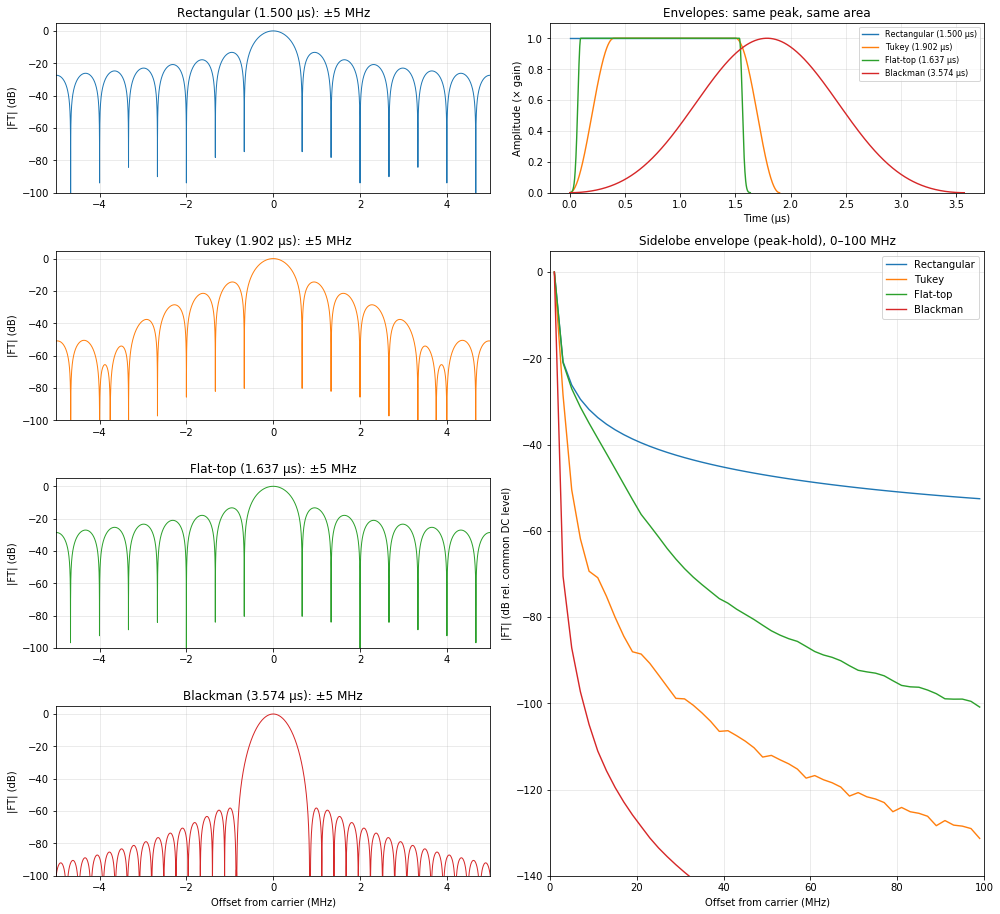

  0%|          | 0/100000 [00:00<?, ?it/s]

In [28]:


# ----------------------------------------------------------------------------
# Main (expects `soc` and `soccfg` to already exist when RUN_ON_HW is True)
# ----------------------------------------------------------------------------
def main():
    if RUN_ON_HW:
        ch = cfg["gen_ch"]
        if check_gen(soccfg, ch):
            gencfg = soccfg["gens"][ch]
            spc, f_fabric = gencfg["samps_per_clk"], gencfg["f_fabric"]
            Prog = build_program_class()
        else:
            spc, f_fabric = 16, 614.4             # nominal rate; nothing goes to envelope memory
            Prog = build_mux_rect_class()
        prog = Prog(soccfg, reps=cfg["reps"], final_delay=cfg["final_delay"], cfg=cfg)
#         print(prog)
    else:
        # nominal ZCU216 full-speed generator: 614.4 MHz fabric x 16 = 9830.4 MS/s
        spc, f_fabric = 16, 614.4

    pulses, _ = design_pulses(cfg, f_fabric, spc)
    pulses = {name: pulses[name] for name in PULSE_ORDER}
    print_design(pulses, cfg)
    plot_spectra(pulses, f_fabric * spc)

    if RUN_ON_HW:
        prog.run_rounds(soc, rounds=1, progress=True)


if __name__ == "__main__":
    main()